# Этап 8: прогноз спроса двухэтапной LightGBM

Notebook показывает модель из текста ВКР на одном источнике данных: что за метки,
как модель обучена, чем она лучше или хуже базовых оценок и откуда берётся прогноз
конкретного объекта. Вся логика — в пакете `sppr_ml`; здесь только вызовы и графики.

Модель: классификатор оценивает $p = P(N \ge 1)$, регрессор на строках с $N \ge 1$
оценивает $\hat y \approx N - 1$, условное число чтений $m = 1 + \hat y$, прогноз
$\hat N = p \cdot m$ за горизонт $H = 1$ ч.

Test-период здесь не открывается: подбор и все метрики — на validation.

In [1]:
from pathlib import Path
import json, math
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())
SOURCE = "shift-0"                      # любой каталог из build/ml-medium
DATA = ROOT / "build/ml-medium" / SOURCE
MODEL = ROOT / "build/ml-models" / SOURCE

from sppr_ml import data, baselines, metrics, evaluate
from sppr_ml.data import FEATURES

rows = data.load(DATA, train_every=900)
train, validation = rows.of("train"), rows.of("validation")
manifest = json.loads((MODEL / "manifest.json").read_text())
report = json.loads((MODEL / "report.json").read_text())
print(f"{SOURCE}: train {len(train)} строк, validation {len(validation)} строк, модель {manifest['model_version']}")

Matplotlib is building the font cache; this may take a moment.


shift-0: train 189000 строк, validation 93000 строк, модель lgbm-hurdle-v1-shift-0-62138e95c711bd75


## 1. Метки

Метка — число клиентских чтений объекта за следующий час после среза. Доля нулей
решает, нужен ли классификатор: если нулей почти нет, задача сводится к регрессии.

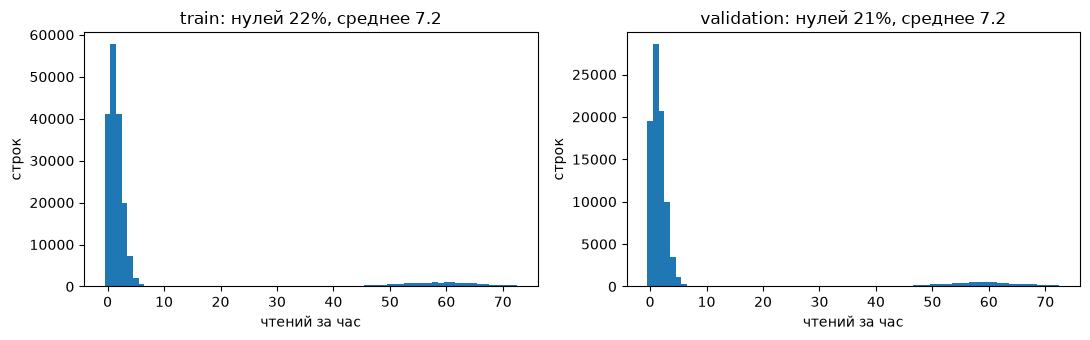

{'train': {'rows': 189000,
  'zero_share': 0.2174021164021164,
  'mean': 7.2,
  'p50': 1.0,
  'p90': 31.0,
  'p99': 69.0,
  'max': 89.0},
 'validation': {'rows': 93000,
  'zero_share': 0.21010752688172044,
  'mean': 7.2,
  'p50': 1.0,
  'p90': 12.400000000139698,
  'p99': 69.0,
  'max': 88.0}}

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (name, part) in zip(axes, [("train", train), ("validation", validation)]):
    ax.hist(part.reads, bins=np.arange(0, np.percentile(part.reads, 99.5) + 2) - 0.5)
    ax.set_title(f"{name}: нулей {np.mean(part.reads == 0):.0%}, среднее {part.reads.mean():.1f}")
    ax.set_xlabel("чтений за час"); ax.set_ylabel("строк")
plt.tight_layout(); plt.show()
report["labels"]

## 2. Модель

Гиперпараметры выбраны по сетке на validation (критерий — `Cov_K`, при равенстве Brier),
число деревьев — ранней остановкой на последних 8 ч train.

In [3]:
classifier = lgb.Booster(model_file=str(MODEL / "classifier.txt"))
regressor = lgb.Booster(model_file=str(MODEL / "regressor.txt"))
p = classifier.predict(validation.x)
excess = regressor.predict(validation.x)
expected = p * (1 + excess)
print("параметры:", report["best"]["params"], "деревьев:", report["best"]["rounds"])
print(f"перебрано вариантов: {len(report['trials'])}, обучение {report['seconds']:.0f} с, пик памяти {report['peak_rss_mib']:.0f} МиБ")

параметры: {'num_leaves': 15, 'learning_rate': 0.03, 'min_data_in_leaf': 200, 'lambda_l2': 0.0} деревьев: {'classifier': 146, 'regressor': 473}
перебрано вариантов: 24, обучение 161 с, пик памяти 477 МиБ


## 3. Сравнение с базовыми оценками

`Cov_K` — доля будущих чтений, пришедшихся на K объектов с наибольшим прогнозом
(K = вместимость HOT, 9,21 % каталога). «Оракул» знает будущее и даёт потолок.
PR-AUC и Brier оценивают классификатор; у базовых оценок $p = 1 - e^{-\hat N}$.

In [4]:
names = list(report["scores"])
print(f"{'оценка':10s} {'Cov_K':>7s} {'95% ДИ':>15s} {'оракул':>7s} {'PR-AUC':>7s} {'Brier':>7s}")
for n in names:
    s = report["scores"][n]
    fmt = lambda v, d=3: "—" if v is None else f"{v:.{d}f}"
    print(f"{n:10s} {fmt(s['coverage']):>7s} {fmt(s['coverage_ci'][0])}–{fmt(s['coverage_ci'][1]):>7s} "
          f"{fmt(s['oracle_coverage']):>7s} {fmt(s['pr_auc']):>7s} {fmt(s['brier'], 4):>7s}")
d = report["versus_best_baseline"]
print(f"\nмодель − {d['baseline']}: {d['coverage']:+.4f} (95% ДИ {d['low']:+.4f}…{d['high']:+.4f})")

оценка       Cov_K          95% ДИ  оракул  PR-AUC   Brier
lgbm         0.745 0.728–  0.753   0.768   0.848  0.1616
ewma         0.717 0.683–  0.744   0.768   0.848  0.1938
frequency    0.369 0.300–  0.439   0.768   0.826  0.1695
age          0.089 0.084–  0.094   0.768   0.790  0.2098
recency      0.552 0.537–  0.562   0.768   0.834  0.1677

модель − ewma: +0.0276 (95% ДИ +0.0045…+0.0585)


Кривая `Cov_K` по размеру HOT показывает, где модель выигрывает: при маленьком HOT
важен порядок самых популярных объектов, при большом — отделение читаемых от нечитаемых.

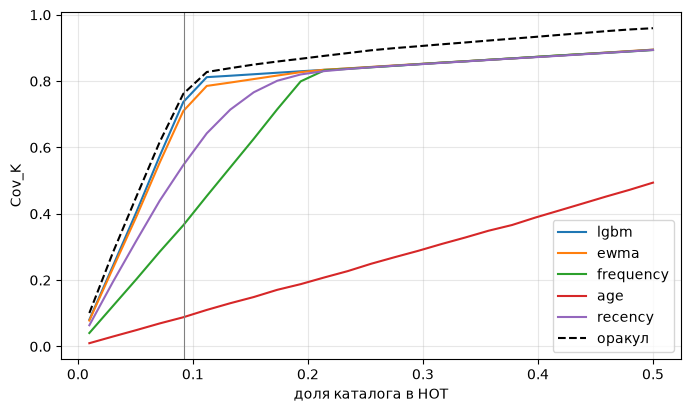

In [5]:
shares = np.linspace(0.01, 0.5, 25)
estimates = {"lgbm": expected, **{k: f(validation) for k, f in baselines.fitted(train).items()}}
plt.figure(figsize=(8, 4.5))
for name, e in estimates.items():
    plt.plot(shares, [metrics.coverage(validation.at, validation.reads, e, share=s) for s in shares], label=name)
plt.plot(shares, [metrics.coverage_parts(validation.at, validation.reads, validation.reads, share=s)[1].sum()
                  / validation.reads.sum() for s in shares], "k--", label="оракул")
plt.axvline(metrics.HOT_SHARE, color="grey", lw=0.8)
plt.xlabel("доля каталога в HOT"); plt.ylabel("Cov_K"); plt.legend(); plt.grid(alpha=0.3); plt.show()

Калибровка: если модель говорит «вероятность чтения 0,3», читаться должна примерно
треть таких объектов. Точки на диагонали — хорошая калибровка (это и измеряет Brier).

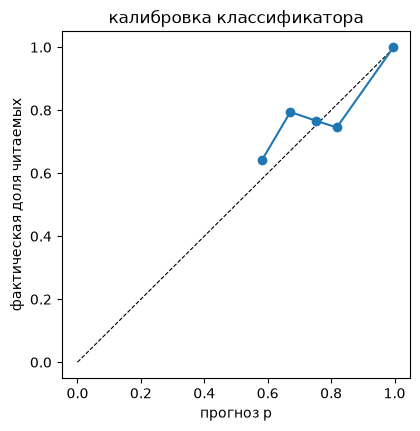

In [6]:
bins = np.linspace(0, 1, 11)
idx = np.digitize(p, bins[1:-1])
has = validation.reads > 0
xs = [p[idx == i].mean() for i in range(10) if (idx == i).sum() > 50]
ys = [has[idx == i].mean() for i in range(10) if (idx == i).sum() > 50]
plt.figure(figsize=(4.5, 4.5)); plt.plot([0, 1], [0, 1], "k--", lw=0.8); plt.plot(xs, ys, "o-")
plt.xlabel("прогноз p"); plt.ylabel("фактическая доля читаемых"); plt.title("калибровка классификатора"); plt.show()

## 4. Что модель использует

Важность признака — суммарное уменьшение потерь во всех его разбиениях (gain).

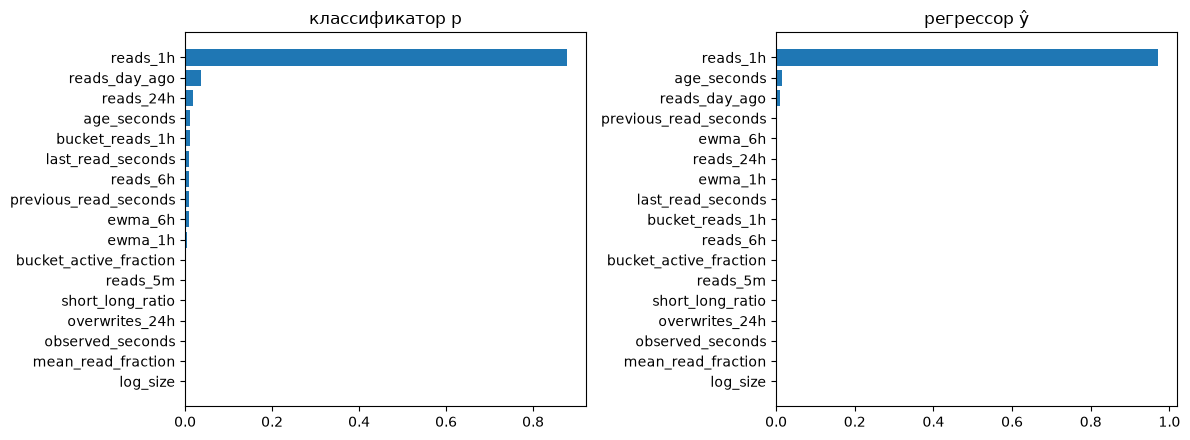

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (title, booster) in zip(axes, [("классификатор p", classifier), ("регрессор ŷ", regressor)]):
    gain = booster.feature_importance("gain")
    order = np.argsort(gain)
    ax.barh(np.array(FEATURES)[order], gain[order] / gain.sum()); ax.set_title(title)
plt.tight_layout(); plt.show()

## 5. Разбор трёх объектов

Для каждой строки: признаки, путь $p \to m \to \hat N$, оценка EWMA для сравнения и
вклады признаков. Вклады складываются в «сырой» выход: для классификатора это логит
$\log\frac{p}{1-p}$, для регрессора — $\log \hat y$. Первая строка — смещение (bias),
одинаковое для всех объектов.

In [8]:
def explain(i, title):
    x = validation.x[i:i + 1]
    cls_c = classifier.predict(x, pred_contrib=True)[0]
    reg_c = regressor.predict(x, pred_contrib=True)[0]
    p_i, y_i = p[i], excess[i]
    print(f"=== {title}: {validation.version[i]} в {np.datetime64(int(validation.at[i]), 's')}")
    print(f"факт: {validation.reads[i]:.0f} чтений | p = {p_i:.3f}, m = 1 + {y_i:.2f} = {1 + y_i:.2f}, "
          f"N̂ = {p_i * (1 + y_i):.2f} | EWMA = {validation.ewma[i]:.2f}")
    print(f"логит p = {cls_c.sum():+.3f} (sigmoid → {1 / (1 + math.exp(-cls_c.sum())):.3f}); "
          f"log ŷ = {reg_c.sum():+.3f} (exp → {math.exp(reg_c.sum()):.2f})")
    print(f"{'признак':24s} {'значение':>12s} {'вклад в логит p':>16s} {'вклад в log ŷ':>14s}")
    print(f"{'(смещение)':24s} {'':>12s} {cls_c[-1]:>+16.3f} {reg_c[-1]:>+14.3f}")
    for j in np.argsort(-np.abs(cls_c[:-1]) - np.abs(reg_c[:-1]))[:7]:
        v = validation.x[i, j]
        print(f"{FEATURES[j]:24s} {'нет' if math.isnan(v) else f'{v:.3g}':>12s} {cls_c[j]:>+16.3f} {reg_c[j]:>+14.3f}")
    print()

zero = np.flatnonzero(validation.reads == 0)
explain(zero[np.argmin(p[zero])] if len(zero) else int(np.argmin(expected)), "ноль чтений")
explain(int(np.argmax(validation.reads)), "самый востребованный")
explain(int(np.argmax(np.abs(expected - validation.reads))), "самая большая ошибка")

=== ноль чтений: v-00779 в 2026-10-03T00:45:00
факт: 0 чтений | p = 0.547, m = 1 + 1.19 = 2.19, N̂ = 1.20 | EWMA = 36.68
логит p = +0.188 (sigmoid → 0.547); log ŷ = +0.176 (exp → 1.19)
признак                      значение  вклад в логит p  вклад в log ŷ
(смещение)                                      +1.611         +0.468
reads_1h                           13           +0.445         +1.722
reads_day_ago                      66           -0.633         -1.505
reads_6h                          311           -0.668         +0.002
reads_24h                    1.39e+03           -0.269         +0.051
ewma_6h                          51.4           -0.076         -0.199
previous_read_seconds        2.28e+03           -0.012         -0.161
age_seconds                  1.76e+05           -0.008         -0.160

=== самый востребованный: v-00989 в 2026-10-03T21:15:00
факт: 88 чтений | p = 0.997, m = 1 + 58.07 = 59.07, N̂ = 58.91 | EWMA = 56.76
логит p = +5.886 (sigmoid → 0.997); log ŷ = +4.062

## 6. Все источники

Сводка по всем обученным моделям: разность `Cov_K` модели и лучшей базовой оценки
с 95 % интервалом парного bootstrap по моментам среза. Если интервал содержит ноль,
выигрыш не доказан.

In [9]:
for path in sorted((ROOT / "build/ml-models").glob("*/report.json")):
    r = json.loads(path.read_text()); d = r["versus_best_baseline"]
    verdict = "лучше" if d["low"] > 0 else ("хуже" if d["high"] < 0 else "не доказано")
    print(f"{r['source']:12s} против {d['baseline']:10s} {d['coverage']:+.4f} [{d['low']:+.4f}…{d['high']:+.4f}] {verdict}")

burst-0      против frequency  -0.0001 [-0.0009…+0.0007] не доказано
decay-0      против frequency  -0.0021 [-0.0025…-0.0017] хуже
periodic-0   против frequency  -0.0006 [-0.0012…-0.0001] хуже
shift-0      против ewma       +0.0276 [+0.0045…+0.0585] лучше
stable-0     против frequency  +0.0007 [-0.0001…+0.0015] не доказано
uniform-0    против frequency  -0.0001 [-0.0009…+0.0007] не доказано


## Что понять

- Что учится в деревьях: каждое дерево — набор порогов по признакам; бустинг добавляет
  деревья, исправляющие ошибки предыдущих.
- Зачем две модели: «будет ли спрос» и «сколько» ведут себя по-разному; при множестве
  нулей одна пуассоновская модель плохо отделяет нечитаемые объекты.
- PR-AUC — различение читаемых объектов при редких положительных; Brier — калибровка
  вероятности; `Cov_K` — то, что нужно планировщику: доля чтений, попавших в HOT.
- Качество прогноза ≠ выигрыш по задержке: план ограничен бюджетом копирования и
  интервалом между переносами, и даже идеальный прогноз применяется с опозданием.